# Why is validation perfect? Baseline diagnostics

This supplementary experiment preserves the primary baseline and its fixed split.
It audits fit inputs, reconstructs training-only TF-IDF vocabulary/IDF, reproduces
the six model-selection fits and five OOF fits with fit-call tracing, runs 20
shuffled-label controls, and measures sensitivity to training/validation overlap.

The original settings and threshold are fixed. All 192 validation dialogues remain
in every experiment. **Official test text is neither loaded nor scored here.**

Two sensitivity policies are declared before fitting: remove four previously
reviewed near-verbatim training counterparts; and a broader stress test removing
all training counterparts to validation flagged at cosine ≥0.90. The latter is a
threshold stress test, not a claim that every flagged pair is a duplicate.

Run on a Colab A100. Upload `outputs/text/diagnostic_inputs.zip` to
`/content/diagnostic_inputs.zip` using the documented CLI workflow first. Source
implementation is embedded. This notebook uses synthetic data; it cannot establish
same-topic intent understanding or real-world reliability. An independently
reviewed challenge set has not yet been constructed/evaluated.


In [2]:
import os
from pathlib import Path
import subprocess
import sys

# Keep the default for the requested remote run. Set the environment variable to 0
# only for an explicitly labelled local smoke run.
REQUIRE_COLAB_A100 = os.environ.get("SCAM_REQUIRE_COLAB_A100", "1") == "1"
try:
    gpu = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True
    ).strip()
except (OSError, subprocess.SubprocessError):
    gpu = "unavailable"
is_colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
print({"Colab runtime": is_colab, "GPU": gpu, "Python": sys.version})
if REQUIRE_COLAB_A100:
    assert is_colab and "A100" in gpu, "Connect a Colab A100 kernel before running."


{'Colab runtime': True, 'GPU': 'NVIDIA A100-SXM4-40GB, 40960 MiB', 'Python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'}


## Pinned dependencies

In [3]:
requirements = '# Isolated baseline/Colab environment. Shared pyproject.toml and uv.lock are unchanged.\nnumpy==2.2.6\npandas==2.3.3\nscipy==1.18.1\nscikit-learn==1.7.2\nmatplotlib==3.10.7\njoblib==1.6.0\nnbformat==5.10.4\nnbclient==0.10.2\nipykernel==7.0.1\n'
if is_colab:
    import importlib.metadata
    requested = [line for line in requirements.splitlines() if line and not line.startswith("#")]
    mismatches = []
    for item in requested:
        name, expected = item.split("==")
        try:
            actual = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            actual = None
        if actual != expected:
            mismatches.append(item)
    if mismatches:
        loaded_before_install = [name for name in ("numpy", "pandas", "scipy", "sklearn", "matplotlib") if name in sys.modules]
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *requested], check=True)
        if loaded_before_install:
            raise RuntimeError("Dependencies installed. Restart the kernel and Run All before importing numerical libraries.")

ROOT = Path.cwd()
if not is_colab:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), ROOT)
DATA_DIR = ROOT / "data/scam_dialogue"
OUTPUT_DIR = ROOT / "outputs/text/diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts:", OUTPUT_DIR)


Artifacts: /content/outputs/text/diagnostics


## Frozen reference and implementation

In [4]:
import hashlib
import zipfile

inputs_zip = Path("/content/diagnostic_inputs.zip") if is_colab else ROOT / "outputs/text/diagnostic_inputs.zip"
assert hashlib.sha256(inputs_zip.read_bytes()).hexdigest() == 'f57cd60344113d2429ef9b776a426921fa37b38f527703a00759e1b7ca335cc4', "Reference input archive changed"
INPUT_DIR = ROOT / "outputs/text/diagnostic_inputs"
INPUT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(inputs_zip) as package:
    assert all(not Path(name).is_absolute() and ".." not in Path(name).parts for name in package.namelist())
    package.extractall(INPUT_DIR)

# Local files are not automatically visible to a remote VS Code notebook kernel.
CODE_DIR = ROOT / "outputs/text/diagnostic_code"
MODULE_DIR = CODE_DIR / "src/text"
MODULE_DIR.mkdir(parents=True, exist_ok=True)
(MODULE_DIR.parent / "__init__.py").write_text("")
(MODULE_DIR / "__init__.py").write_text("")
(MODULE_DIR / "baseline.py").write_text('"""Reproducible scam-text audit and train-only TF-IDF baseline.\n\nRun from the repository root: python -m src.text.baseline\nOnly validation metrics are computed at this milestone; test remains sealed.\n"""\n\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport importlib.metadata\nimport json\nimport platform\nimport re\nimport subprocess\nimport sys\nimport unicodedata\nfrom pathlib import Path\nfrom urllib.request import urlopen\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import (\n    ConfusionMatrixDisplay, confusion_matrix, f1_score,\n    precision_score, recall_score,\n)\nfrom sklearn.model_selection import StratifiedGroupKFold, train_test_split\nfrom sklearn.pipeline import Pipeline\n\nREVISION = "321b961b5ae353e19ed479b960658dcd223d5e06"\nDATASET = "BothBosu/scam-dialogue"\nSOURCE_SHA256 = {\n    "scam-dialogue_train.csv": "cda5d42d15fd341208a25466d9ea279de905a640bd153f67b5c29743520f96f8",\n    "scam-dialogue_test.csv": "17a9e52e90d893541d76dbb4588cb75b1a66ef2474ef2619d56feff5b8d5aec0",\n}\nSEED = 42\nNEAR_THRESHOLD = 0.90\nTURN = re.compile(r"\\b(?:caller|receiver)\\s*:", re.IGNORECASE)\n\n\ndef sha256(value: str | bytes) -> str:\n    return hashlib.sha256(value.encode("utf-8") if isinstance(value, str) else value).hexdigest()\n\n\ndef normalized(text: str) -> str:\n    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())\n\n\ndef turns(text: str) -> list[str]:\n    starts = [m.start() for m in TURN.finditer(text)]\n    if not starts:\n        return [text]\n    starts[0] = 0  # Preserve any preamble.\n    return [text[a:b].strip() for a, b in zip(starts, starts[1:] + [len(text)])]\n\n\ndef prefix(text: str, fraction: float) -> str:\n    items = turns(text)\n    return " ".join(items[:max(1, int(np.ceil(len(items) * fraction)))])\n\n\ndef write_json(path: Path, value) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\\n", encoding="utf-8")\n\n\ndef runtime_info(require_a100: bool = False) -> dict:\n    try:\n        result = subprocess.run(\n            ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],\n            capture_output=True, text=True, timeout=15, check=True,\n        )\n        gpu = result.stdout.strip()\n    except (OSError, subprocess.SubprocessError):\n        gpu = "unavailable"\n    # This detects the remote runtime, including a VS Code Colab kernel.\n    import os\n    colab = bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))\n    info = {\n        "python": sys.version, "platform": platform.platform(), "gpu": gpu,\n        "colab_runtime": colab,\n        "classifier_compute": "CPU (scikit-learn TF-IDF/logistic regression)",\n        "versions": {name: importlib.metadata.version(name) for name in\n                     ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib"]},\n    }\n    if require_a100 and not (colab and "A100" in gpu):\n        raise RuntimeError(f"A Colab A100 runtime is required; observed: {info}")\n    return info\n\n\ndef load_data(data_dir: Path, output_dir: Path) -> pd.DataFrame:\n    data_dir.mkdir(parents=True, exist_ok=True)\n    frames, files = [], {}\n    for source, count in [("train", 1280), ("test", 320)]:\n        name = f"scam-dialogue_{source}.csv"\n        # Cache names are revision-scoped so a different snapshot cannot be reused silently.\n        path = data_dir / REVISION / name\n        path.parent.mkdir(parents=True, exist_ok=True)\n        if not path.exists():\n            url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{name}"\n            with urlopen(url, timeout=120) as response:\n                payload = response.read()\n            path.write_bytes(payload)\n        files[name] = sha256(path.read_bytes())\n        if files[name] != SOURCE_SHA256[name]:\n            raise ValueError(f"Dataset checksum mismatch: {path}; investigate cache/source before proceeding")\n        frame = pd.read_csv(path, keep_default_na=False)\n        if set(frame.columns) != {"dialogue", "type", "label"} or len(frame) != count:\n            raise ValueError(f"Unexpected schema/count in {name}: {frame.shape}, {frame.columns}")\n        if not frame.label.isin([0, 1]).all():\n            raise ValueError("Labels must be 0/1")\n        frame["source_split"] = source\n        frame["source_row"] = np.arange(len(frame))  # zero-based CSV data-row ordinal\n        frame["text_sha256"] = frame.dialogue.map(sha256)\n        frame["normalized_sha256"] = frame.dialogue.map(lambda s: sha256(normalized(s)))\n        frame["dialogue_id"] = [f"scam-{source}-{i:04d}-{digest[:16]}"\n                                for i, digest in zip(frame.source_row, frame.text_sha256)]\n        frame["split"] = source\n        frames.append(frame)\n    data = pd.concat(frames, ignore_index=True)\n    train_indices = data.index[data.source_split.eq("train")]\n    _, validation = train_test_split(\n        train_indices, test_size=192, random_state=SEED,\n        stratify=data.loc[train_indices, "label"],\n    )\n    data.loc[validation, "split"] = "validation"\n    data["included"] = True\n    data["exclusion_reason"] = ""\n    empty = data.dialogue.str.strip().eq("")\n    if empty[data.split.eq("test")].any():\n        raise ValueError("Missing test text: preserve test and investigate before fitting")\n    data.loc[empty, ["included", "exclusion_reason"]] = [False, "missing_text"]\n    # Preserve test, then validation; remove exact/whitespace/case duplicates from lower-priority pools.\n    # Similarity matches alone NEVER cause exclusions.\n    priority = {"test": 0, "validation": 1, "train": 2}\n    ordered = data.assign(priority=data.split.map(priority)).sort_values(["priority", "source_row"])\n    for _, group in ordered.loc[~empty.reindex(ordered.index)].groupby("normalized_sha256", sort=False):\n        if len(group) < 2:\n            continue\n        if group.label.nunique() != 1:\n            raise ValueError("Conflicting labels in duplicate group; manual review required")\n        keep = group.iloc[0]\n        for index, row in group.iloc[1:].iterrows():\n            if row.split != "test":\n                data.loc[index, ["included", "exclusion_reason"]] = [\n                    False, f"normalized_duplicate_of:{keep.dialogue_id}"]\n    if not data.dialogue_id.is_unique:\n        raise ValueError("ID collision")\n    manifest_cols = ["dialogue_id", "source_split", "source_row", "text_sha256",\n                     "normalized_sha256", "split", "label", "included", "exclusion_reason"]\n    output_dir.mkdir(parents=True, exist_ok=True)\n    manifest_text = data[manifest_cols].to_csv(index=False, lineterminator="\\n")\n    (output_dir / "split_manifest.csv").write_text(manifest_text, encoding="utf-8", newline="")\n    write_json(output_dir / "dataset_provenance.json", {\n        "dataset": DATASET, "revision": REVISION, "file_sha256": files,\n        "seed": SEED, "validation_size": 192, "stratification": "label",\n        "id_rule": "scam-{published_split}-{zero_based_row:04d}-{raw_text_sha256[:16]}",\n    })\n    return data\n\n\ndef audit(data: pd.DataFrame, output_dir: Path) -> dict:\n    lengths = data[["dialogue_id", "split", "label", "type", "included"]].copy()\n    lengths["characters"] = data.dialogue.str.len()\n    lengths["words"] = data.dialogue.str.split().map(len)\n    lengths["turns"] = data.dialogue.map(lambda s: len(turns(s)))\n    lengths.to_csv(output_dir / "dialogue_lengths.csv", index=False)\n    balance = data.groupby(["split", "included", "label", "type"]).size().rename("count").reset_index()\n    balance.to_csv(output_dir / "class_type_counts.csv", index=False)\n    duplicate_rows = data[data.duplicated("normalized_sha256", keep=False)]\n    duplicate_rows.drop(columns="dialogue").to_csv(output_dir / "exact_duplicate_rows.csv", index=False)\n    # Stateless character hashing is an audit instrument only, never a model input.\n    hasher = HashingVectorizer(analyzer="char", ngram_range=(5, 5), n_features=2**18,\n                               alternate_sign=False, lowercase=True, norm="l2")\n    vectors = hasher.transform(data.dialogue.map(normalized))\n    similarity = (vectors @ vectors.T).toarray()\n    upper = np.triu(np.ones(similarity.shape, dtype=bool), 1)\n    cross = data.split.to_numpy()[:, None] != data.split.to_numpy()[None, :]\n    indices = np.argwhere(upper & cross & (similarity >= NEAR_THRESHOLD))\n    records = []\n    for i, j in indices:\n        a, b = data.iloc[i], data.iloc[j]\n        records.append({"id_a": a.dialogue_id, "id_b": b.dialogue_id,\n                        "split_a": a.split, "split_b": b.split,\n                        "similarity": float(similarity[i, j]),\n                        "normalized_exact": a.normalized_sha256 == b.normalized_sha256,\n                        "included_a": bool(a.included), "included_b": bool(b.included)})\n    columns = ["id_a", "id_b", "split_a", "split_b", "similarity", "normalized_exact", "included_a", "included_b"]\n    pairs = pd.DataFrame(records, columns=columns).sort_values("similarity", ascending=False)\n    pairs.to_csv(output_dir / "near_duplicate_candidates.csv", index=False)\n    # Keep full matching text locally for actual human inspection, including the most similar\n    # pair for each split boundary even if no pair clears the candidate threshold.\n    review = pairs.to_dict("records")\n    for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:\n        a = data.index[data.split.eq(left)].to_numpy()\n        b = data.index[data.split.eq(right)].to_numpy()\n        local_i, local_j = np.unravel_index(np.argmax(similarity[np.ix_(a, b)]), (len(a), len(b)))\n        i, j = a[local_i], b[local_j]\n        review.append({"id_a": data.iloc[i].dialogue_id, "id_b": data.iloc[j].dialogue_id,\n                       "similarity": float(similarity[i, j]), "boundary_maximum": f"{left}/{right}"})\n    lookup = data.set_index("dialogue_id")\n    for row in review:\n        row["dialogue_a"] = lookup.loc[row["id_a"], "dialogue"]\n        row["dialogue_b"] = lookup.loc[row["id_b"], "dialogue"]\n    write_json(output_dir / "similarity_review_text.json", review)\n    summary = {\n        "raw_rows": len(data), "missing_text": int(data.dialogue.str.strip().eq("").sum()),\n        "planned_counts": data.split.value_counts().to_dict(),\n        "included_counts": data[data.included].split.value_counts().to_dict(),\n        "excluded_count": int((~data.included).sum()),\n        "raw_exact_duplicate_groups": int(data.groupby("text_sha256").size().gt(1).sum()),\n        "normalized_duplicate_groups": int(data.groupby("normalized_sha256").size().gt(1).sum()),\n        "cross_split_candidates": len(pairs), "candidate_threshold": NEAR_THRESHOLD,\n        "audit_similarity": "cosine of stateless 2^18-bin character 5-gram hashes; collisions possible",\n        "length_summary": lengths[["characters", "words", "turns"]].describe().to_dict(),\n        "exclusion_policy": "Missing text and normalized exact duplicates only; test always retained. No similarity-only exclusions.",\n        "wordpiece_lengths": "Deferred to the MiniLM milestone; word counts are not wordpiece counts.",\n    }\n    write_json(output_dir / "audit_summary.json", summary)\n    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))\n    for split, group in lengths.groupby("split"):\n        axes[0].hist(group.words, bins=25, histtype="step", label=split)\n        axes[1].hist(group.turns, bins=20, histtype="step", label=split)\n    axes[0].set(xlabel="Whitespace-separated words", ylabel="Dialogues")\n    axes[1].set(xlabel="Speaker turns", ylabel="Dialogues")\n    axes[0].legend()\n    fig.tight_layout()\n    fig.savefig(output_dir / "dialogue_lengths.png", dpi=160)\n    plt.close(fig)\n    return summary\n\n\ndef metrics(labels, scores, threshold: float) -> dict:\n    labels, scores = np.asarray(labels), np.asarray(scores)\n    predictions = scores >= threshold\n    return {"n": len(labels), "scam_support": int(labels.sum()),\n            "precision": float(precision_score(labels, predictions, zero_division=0)),\n            "recall": float(recall_score(labels, predictions, zero_division=0)),\n            "f1": float(f1_score(labels, predictions, zero_division=0)),\n            "accuracy": float(np.mean(labels == predictions)),\n            "false_positive_rate": float(np.mean(predictions[labels == 0])) if np.any(labels == 0) else None,\n            "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]).tolist()}\n\n\ndef train_baseline(data: pd.DataFrame, output_dir: Path) -> tuple[Pipeline, dict]:\n    train = data[data.included & data.split.eq("train")].copy()\n    validation = data[data.included & data.split.eq("validation")].copy()\n    candidates, fitted = [], []\n    for ngram in [(1, 1), (1, 2)]:\n        for c in [0.1, 1.0, 10.0]:\n            model = Pipeline([\n                ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)),\n                ("classifier", LogisticRegression(C=c, max_iter=2000, solver="liblinear", random_state=SEED)),\n            ])\n            # dialogue is the ONLY feature; no type, ID, split, or target enters the pipeline.\n            model.fit(train.dialogue, train.label)\n            score = model.predict_proba(validation.dialogue)[:, 1]\n            result = {"ngram_max": ngram[1], "C": c, **metrics(validation.label, score, 0.5)}\n            candidates.append(result)\n            fitted.append((model, score))\n    table = pd.DataFrame(candidates).drop(columns="confusion_matrix")\n    table.to_csv(output_dir / "validation_search.csv", index=False)\n    # Deterministic ties: simpler ngrams, then stronger regularization (loop order).\n    best = max(range(len(candidates)), key=lambda i: candidates[i]["f1"])\n    model, scores = fitted[best]\n    thresholds = sorted(set([0.5, 0.0, 1.0, *map(float, scores)]))\n    threshold = max(thresholds, key=lambda t: (\n        f1_score(validation.label, scores >= t, zero_division=0), -abs(t - 0.5), t))\n    result = {"model": "tfidf_logreg", "seed": SEED,\n              "ngram_range": [1, candidates[best]["ngram_max"]], "C": candidates[best]["C"],\n              "threshold": threshold, "threshold_rule": "score >= threshold",\n              "selection": "validation F1 at 0.5, ties simplest ngrams then smallest C; threshold then maximizes validation F1 with ties closest to 0.5",\n              "fit_n": len(train), "validation_at_0_5": metrics(validation.label, scores, 0.5),\n              "validation": metrics(validation.label, scores, threshold),\n              "test_evaluated": False, "dataset_revision": REVISION}\n    model_path = output_dir / "tfidf_logreg.joblib"\n    joblib.dump({"pipeline": model, "config": result}, model_path)\n    result["saved_model_sha256"] = sha256(model_path.read_bytes())\n    write_json(output_dir / "frozen_config.json", result)\n    validation = validation.assign(scam_score=scores, prediction=(scores >= threshold).astype(int))\n    validation.drop(columns="dialogue").to_csv(output_dir / "validation_predictions.csv", index=False)\n    by_type = []\n    for kind, group in validation.groupby("type"):\n        # Types are single-class; precision/F1 are undefined for benign-only groups.\n        row = {"type": kind, **metrics(group.label, group.scam_score, threshold)}\n        if row["scam_support"] == 0:\n            row.update(precision=None, recall=None, f1=None)\n        by_type.append(row)\n    pd.DataFrame(by_type).drop(columns="confusion_matrix").to_csv(output_dir / "validation_by_type.csv", index=False)\n    errors = validation[validation.label.ne(validation.prediction)].copy()\n    errors["error_kind"] = np.where(errors.label.eq(0), "false_positive", "false_negative")\n    errors.to_csv(output_dir / "validation_errors.csv", index=False)\n    fig, ax = plt.subplots(figsize=(4.5, 4))\n    ConfusionMatrixDisplay.from_predictions(validation.label, validation.prediction,\n        labels=[0, 1], display_labels=["Benign", "Scam"], ax=ax, colorbar=False)\n    ax.set_title(f"Validation, threshold={threshold:.3f}")\n    fig.tight_layout()\n    fig.savefig(output_dir / "validation_confusion_matrix.png", dpi=160)\n    plt.close(fig)\n    return model, result\n\n\ndef export_oof(data: pd.DataFrame, model: Pipeline, output_dir: Path) -> pd.DataFrame:\n    """Fixed selected settings; refit vocabulary, IDF, classifier inside each fold."""\n    train = data[data.included & data.split.eq("train")].copy().reset_index(drop=True)\n    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)\n    train["fold"] = -1\n    train["scam_score"] = np.nan\n    for fold, (fit, heldout) in enumerate(splitter.split(train.dialogue, train.label, train.normalized_sha256)):\n        assert set(train.iloc[fit].normalized_sha256).isdisjoint(train.iloc[heldout].normalized_sha256)\n        fold_model = clone(model).fit(train.iloc[fit].dialogue, train.iloc[fit].label)\n        train.loc[heldout, "scam_score"] = fold_model.predict_proba(train.iloc[heldout].dialogue)[:, 1]\n        train.loc[heldout, "fold"] = fold\n    validation = data[data.included & data.split.eq("validation")].copy()\n    validation["fold"] = -1  # -1 means classifier fitted on the complete eligible training partition\n    validation["scam_score"] = model.predict_proba(validation.dialogue)[:, 1]\n    scores = pd.concat([train, validation], ignore_index=True).assign(model="tfidf_logreg")\n    scores = scores[["dialogue_id", "split", "label", "model", "scam_score", "fold"]]\n    assert scores.dialogue_id.is_unique and scores.scam_score.between(0, 1).all()\n    scores.to_csv(output_dir / "fusion_scores_train_validation.csv", index=False)\n    train[["dialogue_id", "fold"]].to_csv(output_dir / "oof_folds.csv", index=False)\n    return scores\n\n\ndef score_transcripts(bundle_path: str | Path, transcripts: list[str]) -> np.ndarray:\n    """Return uncalibrated scam-intent ranking scores; load only trusted joblib files."""\n    bundle = joblib.load(bundle_path)\n    return bundle["pipeline"].predict_proba(transcripts)[:, 1]\n\n\ndef main() -> None:\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data-dir", type=Path, default=Path("data/scam_dialogue"))\n    parser.add_argument("--output-dir", type=Path, default=Path("outputs/text/baseline"))\n    parser.add_argument("--require-a100", action="store_true")\n    args = parser.parse_args()\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    write_json(args.output_dir / "runtime.json", runtime_info(args.require_a100))\n    data = load_data(args.data_dir, args.output_dir)\n    print(json.dumps(audit(data, args.output_dir), indent=2))\n    model, config = train_baseline(data, args.output_dir)\n    export_oof(data, model, args.output_dir)\n    print(json.dumps(config, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', encoding="utf-8")
(MODULE_DIR / "diagnostics.py").write_text('"""Leakage, shuffled-label controls, and validation-overlap sensitivity.\n\nNever scores the official test set and never overwrites primary artifacts.\n"""\nfrom __future__ import annotations\n\nimport argparse\nfrom collections import Counter\nimport json\nfrom pathlib import Path\nfrom unittest.mock import patch\nfrom urllib.request import urlopen\n\nimport joblib\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import clone\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, roc_auc_score\n\nfrom src.text.baseline import (\n    DATASET, REVISION, SOURCE_SHA256, export_oof, metrics, runtime_info, sha256,\n    train_baseline, write_json,\n)\n\nFIXED_MANIFEST_SHA256 = "1fe25e23bff220b8c26efc211e5f2cc40b18b4d42135af4a80555a49a96e7559"\nPERMUTATION_SEEDS = list(range(20))\n\n\ndef load_development(data_dir: Path, manifest_path: Path) -> pd.DataFrame:\n    """Read only the published training CSV; honor the immutable split manifest."""\n    if sha256(manifest_path.read_bytes()) != FIXED_MANIFEST_SHA256:\n        raise ValueError("Fixed manifest changed")\n    manifest = pd.read_csv(manifest_path, keep_default_na=False)\n    metadata = manifest[manifest.source_split.eq("train")].copy()\n    path = data_dir / REVISION / "scam-dialogue_train.csv"\n    path.parent.mkdir(parents=True, exist_ok=True)\n    if not path.exists():\n        url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/{path.name}"\n        with urlopen(url, timeout=120) as response:\n            path.write_bytes(response.read())\n    if sha256(path.read_bytes()) != SOURCE_SHA256[path.name]:\n        raise ValueError("Training source checksum changed")\n    raw = pd.read_csv(path, keep_default_na=False).assign(source_row=lambda x: np.arange(len(x)))\n    data = raw.merge(metadata, on="source_row", suffixes=("_source", ""), validate="one_to_one")\n    assert len(data) == 1280 and data.label.eq(data.label_source).all()\n    assert data.dialogue.map(sha256).eq(data.text_sha256).all()\n    return data.drop(columns="label_source")\n\n\ndef score_metrics(labels, scores, threshold: float) -> dict:\n    return {**metrics(labels, scores, threshold),\n            "balanced_accuracy": float(balanced_accuracy_score(labels, scores >= threshold)),\n            "roc_auc": float(roc_auc_score(labels, scores))}\n\n\ndef overlap_decisions(review: pd.DataFrame, data: pd.DataFrame) -> pd.DataFrame:\n    """Use prior text review, not validation model errors, to define removals."""\n    included = data[data.included].set_index("dialogue_id")\n    records = []\n    for row in review.itertuples():\n        if not row.included_a or not row.included_b or {row.split_a, row.split_b} != {"train", "validation"}:\n            continue\n        train_id, val_id = (row.id_a, row.id_b) if row.split_a == "train" else (row.id_b, row.id_a)\n        assert included.loc[train_id, "split"] == "train"\n        assert included.loc[val_id, "split"] == "validation"\n        confirmed = row.assessment == "near_verbatim_variant_retained"\n        records.append({\n            "train_id": train_id, "validation_id": val_id, "similarity": row.similarity,\n            "prior_assessment": row.assessment,\n            "review_decision": "confirmed_near_verbatim_variant" if confirmed else "shared_template_or_uncertain_source_identity",\n            "strict_remove": confirmed, "broad_remove": True,\n            "reason": row.reason,\n        })\n    return pd.DataFrame(records)\n\n\ndef audit_implementation(data: pd.DataFrame, reference: Path, output: Path, bundle: dict) -> dict:\n    train = data[data.included & data.split.eq("train")]\n    validation = data[data.included & data.split.eq("validation")]\n    manifest = pd.read_csv(reference / "split_manifest.csv", keep_default_na=False)\n    assert manifest.dialogue_id.is_unique\n    assert set(train.dialogue_id).isdisjoint(validation.dialogue_id)\n    assert set(train.normalized_sha256).isdisjoint(validation.normalized_sha256)\n    assert set(data.split) == {"train", "validation"}\n    lookup = data[data.included].set_index("text_sha256")\n    assert lookup.index.is_unique\n    fit_log = []\n    original_tfidf = TfidfVectorizer.fit_transform\n    original_lr = LogisticRegression.fit\n\n    def observe_tfidf(vectorizer, raw_documents, y=None):\n        documents = list(raw_documents)\n        assert all(isinstance(item, str) for item in documents)\n        hashes = [sha256(item) for item in documents]\n        ids = lookup.loc[hashes, "dialogue_id"].tolist()\n        assert set(ids).issubset(set(train.dialogue_id))\n        fit_log.append({"fit_ids": ids, "n": len(ids), "dialogue_only": True})\n        return original_tfidf(vectorizer, documents, y)\n\n    def observe_lr(classifier, X, y, *args, **kwargs):\n        record = fit_log[-1]\n        expected = train.set_index("dialogue_id").loc[record["fit_ids"], "label"].to_numpy()\n        np.testing.assert_array_equal(np.asarray(y), expected)\n        assert X.shape[0] == len(expected)\n        record["target_alignment_verified"] = True\n        return original_lr(classifier, X, y, *args, **kwargs)\n\n    replay = output / "implementation_replay"\n    replay.mkdir(parents=True, exist_ok=True)\n    with patch.object(TfidfVectorizer, "fit_transform", observe_tfidf), patch.object(LogisticRegression, "fit", observe_lr):\n        replay_model, config = train_baseline(data, replay)\n        replay_scores = export_oof(data, replay_model, replay)\n    assert len(fit_log) == 11  # six grid fits plus five OOF fits\n    for row in fit_log[:6]:\n        assert set(row["fit_ids"]) == set(train.dialogue_id)\n    folds = pd.read_csv(reference / "oof_folds.csv")\n    for fold, row in enumerate(fit_log[6:]):\n        expected = set(folds.loc[folds.fold.ne(fold), "dialogue_id"])\n        heldout = set(folds.loc[folds.fold.eq(fold), "dialogue_id"])\n        assert set(row["fit_ids"]) == expected and set(row["fit_ids"]).isdisjoint(heldout)\n        row["heldout_fold"] = fold\n    reference_scores = pd.read_csv(reference / "fusion_scores_train_validation.csv")\n    joined = reference_scores.merge(replay_scores, on="dialogue_id", suffixes=("_reference", "_replay"), validate="one_to_one")\n    assert len(joined) == len(reference_scores) == 1278\n    np.testing.assert_allclose(joined.scam_score_reference, joined.scam_score_replay, rtol=1e-12, atol=1e-12)\n    for key in ["ngram_range", "C", "threshold", "fit_n", "validation"]:\n        assert config[key] == bundle["config"][key]\n    # Independently reconstruct vocabulary and smoothed IDF from training documents.\n    vectorizer = bundle["pipeline"]["tfidf"]\n    document_frequency = Counter()\n    analyzer = vectorizer.build_analyzer()\n    for text in train.dialogue:\n        document_frequency.update(set(analyzer(text)))\n    expected_terms = {term for term, count in document_frequency.items() if count >= 2}\n    terms = vectorizer.get_feature_names_out()\n    assert set(terms) == expected_terms\n    expected_idf = np.array([np.log((1 + len(train)) / (1 + document_frequency[t])) + 1 for t in terms])\n    np.testing.assert_allclose(vectorizer.idf_, expected_idf, rtol=1e-12, atol=1e-12)\n    write_json(output / "fit_call_trace.json", fit_log)\n    result = {\n        "train_validation_ids_disjoint": True, "normalized_exact_text_disjoint": True,\n        "dialogue_only_fit_inputs_verified": True, "target_alignment_verified": True,\n        "grid_pipeline_fits_verified": 6, "oof_pipeline_fits_verified": 5,\n        "oof_heldout_preprocessing_isolation_verified": True,\n        "training_only_vocabulary_and_idf_verified": True, "vocabulary_size": len(terms),\n        "primary_validation_and_oof_scores_reproduced": True,\n        "test_text_loaded_by_diagnostics": False, "test_scored": False,\n        "limits": "Reproducing the implementation does not resolve shared templates or topic-label confounding.",\n    }\n    write_json(output / "implementation_checks.json", result)\n    return result\n\n\ndef run_diagnostics(data: pd.DataFrame, review: pd.DataFrame, reference: Path, output: Path) -> dict:\n    output.mkdir(parents=True, exist_ok=True)\n    reference_hashes = {p.name: sha256(p.read_bytes()) for p in reference.iterdir() if p.is_file()}\n    config = json.loads((reference / "frozen_config.json").read_text())\n    assert sha256((reference / "tfidf_logreg.joblib").read_bytes()) == config["saved_model_sha256"]\n    bundle = joblib.load(reference / "tfidf_logreg.joblib")\n    pipeline, threshold = bundle["pipeline"], config["threshold"]\n    train = data[data.included & data.split.eq("train")].copy()\n    validation = data[data.included & data.split.eq("validation")].copy()\n    checks = audit_implementation(data, reference, output, bundle)\n    decisions = overlap_decisions(review, data)\n    decisions.to_csv(output / "overlap_decisions.csv", index=False, lineterminator="\\n")\n    permutations, permutation_predictions = [], []\n    for seed in PERMUTATION_SEEDS:\n        shuffled = np.random.default_rng(seed).permutation(train.label.to_numpy())\n        control = clone(pipeline).fit(train.dialogue, shuffled)\n        scores = control.predict_proba(validation.dialogue)[:, 1]\n        row = {"seed": seed, "threshold": threshold,\n               "changed_label_fraction": float(np.mean(shuffled != train.label)),\n               **score_metrics(validation.label, scores, threshold)}\n        permutations.append(row)\n        permutation_predictions.extend({"seed": seed, "dialogue_id": ident, "label": int(label), "scam_score": float(score)}\n                                       for ident, label, score in zip(validation.dialogue_id, validation.label, scores))\n    controls = pd.DataFrame(permutations).drop(columns="confusion_matrix")\n    controls.to_csv(output / "label_shuffle_metrics.csv", index=False)\n    pd.DataFrame(permutation_predictions).to_csv(output / "label_shuffle_predictions.csv", index=False)\n    scenarios = [\n        ("primary_reference", set()),\n        ("reviewed_near_duplicates_removed", set(decisions.loc[decisions.strict_remove, "train_id"])),\n        ("all_flagged_validation_counterparts_removed", set(decisions.train_id)),\n    ]\n    rows, predictions, type_results, removed_rows = [], [], [], []\n    reference_scores = pipeline.predict_proba(validation.dialogue)[:, 1]\n    for name, removed in scenarios:\n        fit = train[~train.dialogue_id.isin(removed)]\n        if name == "primary_reference":\n            fitted = pipeline\n        else:\n            fitted = clone(pipeline).fit(fit.dialogue, fit.label)\n            joblib.dump({"pipeline": fitted, "primary_frozen_config": config, "scenario": name}, output / f"{name}.joblib")\n        scores = fitted.predict_proba(validation.dialogue)[:, 1]\n        row = {"scenario": name, "train_n": len(fit), "train_benign": int(fit.label.eq(0).sum()),\n               "train_scam": int(fit.label.eq(1).sum()), "removed_train_n": len(removed),\n               "threshold": threshold, "changed_predictions_vs_primary": int(np.sum((scores >= threshold) != (reference_scores >= threshold))),\n               "mean_absolute_score_change": float(np.mean(np.abs(scores - reference_scores))),\n               **score_metrics(validation.label, scores, threshold)}\n        rows.append(row)\n        for kind in sorted(validation.type.unique()):\n            mask = validation.type.eq(kind)\n            per_type = metrics(validation.loc[mask, "label"], scores[mask], threshold)\n            if not per_type["scam_support"]:\n                per_type.update(precision=None, recall=None, f1=None)\n            type_results.append({"scenario": name, "type": kind, **per_type})\n        predictions.extend({"scenario": name, "dialogue_id": ident, "label": int(label), "scam_score": float(score)}\n                           for ident, label, score in zip(validation.dialogue_id, validation.label, scores))\n        removed_rows.extend({"scenario": name, "dialogue_id": ident} for ident in sorted(removed))\n    pd.DataFrame(rows).drop(columns="confusion_matrix").to_csv(output / "overlap_sensitivity_metrics.csv", index=False)\n    pd.DataFrame(predictions).to_csv(output / "overlap_sensitivity_predictions.csv", index=False)\n    pd.DataFrame(type_results).drop(columns="confusion_matrix").to_csv(output / "overlap_sensitivity_by_type.csv", index=False)\n    pd.DataFrame(removed_rows).to_csv(output / "removed_training_ids.csv", index=False)\n    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))\n    for ax, column in zip(axes, ["balanced_accuracy", "roc_auc"]):\n        ax.scatter(controls.seed, controls[column], label="Shuffled training labels")\n        ax.axhline(0.5, color="gray", linestyle="--", label="Chance expectation")\n        ax.axhline(1.0, color="black", linestyle=":", label="Primary validation")\n        ax.set(xlabel="Permutation seed", ylabel=column.replace("_", " ").upper(), ylim=(-0.03, 1.03))\n    axes[0].legend(fontsize=8)\n    fig.tight_layout()\n    fig.savefig(output / "label_shuffle_controls.png", dpi=160)\n    plt.close(fig)\n    fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))\n    for ax, row, title in zip(axes, rows, ["Primary reference", "Reviewed near duplicates removed", "All flagged counterparts removed"]):\n        ConfusionMatrixDisplay(np.asarray(row["confusion_matrix"]), display_labels=["Benign", "Scam"]).plot(ax=ax, colorbar=False)\n        ax.set_title(title + f"\\nfit n={row[\'train_n\']}", fontsize=10)\n    fig.tight_layout()\n    fig.savefig(output / "overlap_sensitivity_confusion_matrices.png", dpi=160)\n    plt.close(fig)\n    for filename, digest in reference_hashes.items():\n        assert sha256((reference / filename).read_bytes()) == digest\n    summary = {\n        "protocol": "Fixed primary unigram/C/threshold settings; no retuning; same 192 validation dialogues; official test not read or scored.",\n        "implementation_checks": checks,\n        "label_shuffle": {\n            "seeds": PERMUTATION_SEEDS,\n            "summary": controls[["accuracy", "balanced_accuracy", "roc_auc", "precision", "recall", "f1"]].agg(["mean", "std", "min", "max"]).to_dict(),\n            "interpretation": "A negative control for implementation leakage; F1 has no universal chance value. Topic-correlated validation dialogues can produce substantial between-permutation variation.",\n        },\n        "overlap_sensitivity": rows,\n        "review_scope": {"train_validation_flagged_pairs": len(decisions),\n                         "confirmed_near_verbatim_pairs": int(decisions.strict_remove.sum()),\n                         "validation_membership_unchanged": True,\n                         "original_reference_artifacts_unchanged": True},\n        "test_evaluated": False,\n        "limits": "Even perfect sensitivity performance does not establish same-topic intent discrimination or real-world generalization. No independently reviewed challenge set has been evaluated.",\n    }\n    write_json(output / "diagnostic_summary.json", summary)\n    return summary\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--data-dir", type=Path, default=Path("data/scam_dialogue"))\n    parser.add_argument("--reference-dir", type=Path, default=Path("outputs/text/baseline"))\n    parser.add_argument("--manifest", type=Path, default=Path("notebooks/text/split_manifest.csv"))\n    parser.add_argument("--review", type=Path, default=Path("notebooks/text/audit/similarity_review.csv"))\n    parser.add_argument("--output-dir", type=Path, default=Path("outputs/text/diagnostics"))\n    parser.add_argument("--require-a100", action="store_true")\n    args = parser.parse_args()\n    args.output_dir.mkdir(parents=True, exist_ok=True)\n    write_json(args.output_dir / "runtime.json", runtime_info(args.require_a100))\n    data = load_development(args.data_dir, args.manifest)\n    summary = run_diagnostics(data, pd.read_csv(args.review), args.reference_dir, args.output_dir)\n    print(json.dumps(summary, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n', encoding="utf-8")
sys.path.insert(0, str(CODE_DIR))
from src.text.baseline import runtime_info, write_json
from src.text.diagnostics import load_development, run_diagnostics
import pandas as pd
from IPython.display import Image, display

write_json(OUTPUT_DIR / "runtime.json", runtime_info(require_a100=REQUIRE_COLAB_A100))
display(runtime_info(require_a100=REQUIRE_COLAB_A100))


{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'gpu': 'NVIDIA A100-SXM4-40GB, 40960 MiB',
 'colab_runtime': True,
 'classifier_compute': 'CPU (scikit-learn TF-IDF/logistic regression)',
 'versions': {'numpy': '2.2.6',
  'pandas': '2.3.3',
  'scipy': '1.18.1',
  'scikit-learn': '1.7.2',
  'matplotlib': '3.10.7',
  'joblib': '1.6.0'}}

## Run the fixed audit protocol

Training data only is downloaded from the pinned revision. The saved manifest
governs split membership. Fit tracing checks that inputs are the original dialogue
strings and correctly aligned labels, and that every OOF TF-IDF/classifier fit
excludes its held-out fold. Primary validation and OOF scores must reproduce.

Label controls permute training targets for seeds 0–19, refit the complete Pipeline,
and evaluate against unchanged true validation labels. No settings or thresholds
are selected using control results. Chance expected balanced accuracy/AUC is 0.5;
F1 does not have a universal chance baseline. Wide variation can occur because
the synthetic validation dialogues share topics and templates.


{'train_validation_ids_disjoint': True,
 'normalized_exact_text_disjoint': True,
 'dialogue_only_fit_inputs_verified': True,
 'target_alignment_verified': True,
 'grid_pipeline_fits_verified': 6,
 'oof_pipeline_fits_verified': 5,
 'oof_heldout_preprocessing_isolation_verified': True,
 'training_only_vocabulary_and_idf_verified': True,
 'vocabulary_size': 2290,
 'primary_validation_and_oof_scores_reproduced': True,
 'test_text_loaded_by_diagnostics': False,
 'test_scored': False,
 'limits': 'Reproducing the implementation does not resolve shared templates or topic-label confounding.'}

,seed,threshold,changed_label_fraction,n,scam_support,precision,recall,f1,accuracy,false_positive_rate,balanced_accuracy,roc_auc
0,0,0.5,0.519337,192,96,0.245098,0.260417,0.252525,0.229167,0.802083,0.229167,0.141602
1,1,0.5,0.504604,192,96,0.333333,0.322917,0.328042,0.338542,0.645833,0.338542,0.287869
2,2,0.5,0.506446,192,96,0.385417,0.385417,0.385417,0.385417,0.614583,0.385417,0.353733
3,3,0.5,0.500921,192,96,0.638298,0.625000,0.631579,0.635417,0.354167,0.635417,0.643446
4,4,0.5,0.486188,192,96,0.681818,0.625000,0.652174,0.666667,0.291667,0.666667,0.735135
5,5,0.5,0.493554,192,96,0.536842,0.531250,0.534031,0.536458,0.458333,0.536458,0.593967
6,6,0.5,0.497238,192,96,0.658824,0.583333,0.618785,0.640625,0.302083,0.640625,0.659505
7,7,0.5,0.517495,192,96,0.296703,0.281250,0.288770,0.307292,0.666667,0.307292,0.245117
8,8,0.5,0.511971,192,96,0.277778,0.260417,0.268817,0.291667,0.677083,0.291667,0.204644
9,9,0.5,0.499079,192,96,0.622642,0.687500,0.653465,0.635417,0.416667,0.635417,0.660699


,accuracy,balanced_accuracy,roc_auc,precision,recall,f1
mean,0.521094,0.521094,0.521935,0.521389,0.515104,0.517228
std,0.172066,0.172066,0.221189,0.173262,0.177566,0.173960
min,0.229167,0.229167,0.141602,0.245098,0.260417,0.252525
max,0.755208,0.755208,0.803602,0.757895,0.760417,0.753927


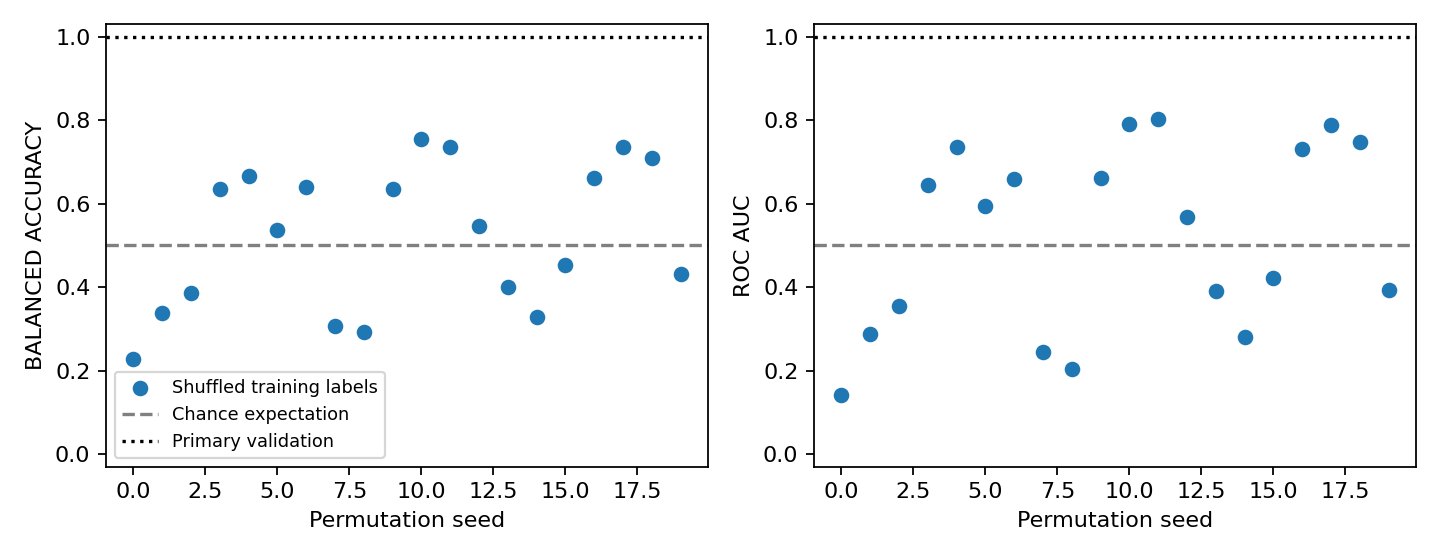

In [5]:
development = load_development(DATA_DIR, INPUT_DIR / "fixed_manifest.csv")
review = pd.read_csv(INPUT_DIR / "review.csv")
summary = run_diagnostics(development, review, INPUT_DIR / "reference", OUTPUT_DIR)
display(summary["implementation_checks"])
display(pd.read_csv(OUTPUT_DIR / "label_shuffle_metrics.csv"))
display(pd.DataFrame(summary["label_shuffle"]["summary"]))
display(Image(filename=str(OUTPUT_DIR / "label_shuffle_controls.png")))


## Overlap sensitivity

The four strict removals were identified by prior text review: same participants,
scenario, turn structure, and content, with only small phrase changes. Review is
by the coding agent; it is not an independent teammate label review. Shared
templates with uncertain identity remain in the strict experiment. The broad
experiment removes every flagged training/validation counterpart regardless of
identity. No validation rows, official test rows, or original artifacts are changed.


,train_id,validation_id,similarity,prior_assessment,review_decision,strict_remove,broad_remove,reason
0,scam-train-1183-8b09a1dfb39581b7,scam-train-1138-42298682e83aee87,0.971229,near_verbatim_variant_retained,confirmed_near_verbatim_variant,True,True,Only a few wording or punctuation changes; ret...
1,scam-train-1193-2c4529f17c450434,scam-train-1138-42298682e83aee87,0.963518,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
2,scam-train-1197-52878a22c6558538,scam-train-1138-42298682e83aee87,0.963476,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
3,scam-train-1185-c4ac611a5cd790e7,scam-train-1200-77840459f9742a4f,0.963357,near_verbatim_variant_retained,confirmed_near_verbatim_variant,True,True,Only a few wording or punctuation changes; ret...
4,scam-train-1167-70273a208309bf3c,scam-train-1138-42298682e83aee87,0.957414,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
5,scam-train-1171-c4c3cbd1793a820e,scam-train-1138-42298682e83aee87,0.955136,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
6,scam-train-1237-a8f2c55bceca33a6,scam-train-1132-50e697894b176209,0.953368,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
7,scam-train-1141-ea4abb9f0b945550,scam-train-1200-77840459f9742a4f,0.951384,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
8,scam-train-1163-d3335575ef537297,scam-train-1132-50e697894b176209,0.950233,shared_synthetic_template_variant,shared_template_or_uncertain_source_identity,False,True,"Common wrong-number script with wording, entit..."
9,scam-train-1142-0fef65a72fcafbce,scam-train-1236-68f54caeeab4f828,0.950066,near_verbatim_variant_retained,confirmed_near_verbatim_variant,True,True,Only a few wording or punctuation changes; ret...


,scenario,train_n,train_benign,train_scam,removed_train_n,threshold,changed_predictions_vs_primary,mean_absolute_score_change,n,scam_support,precision,recall,f1,accuracy,false_positive_rate,balanced_accuracy,roc_auc
0,primary_reference,1086,543,543,0,0.5,0,0.000000,192,96,1.0,1.0,1.0,1.0,0.0,1.0,1.0
1,reviewed_near_duplicates_removed,1082,539,543,4,0.5,0,0.000717,192,96,1.0,1.0,1.0,1.0,0.0,1.0,1.0
2,all_flagged_validation_counterparts_removed,1058,515,543,28,0.5,0,0.005317,192,96,1.0,1.0,1.0,1.0,0.0,1.0,1.0


,scenario,type,n,scam_support,precision,recall,f1,accuracy,false_positive_rate
0,primary_reference,delivery,24,0,NaN,NaN,NaN,1.0,0.0
1,primary_reference,insurance,23,0,NaN,NaN,NaN,1.0,0.0
2,primary_reference,refund,21,21,1.0,1.0,1.0,1.0,NaN
3,primary_reference,reward,19,19,1.0,1.0,1.0,1.0,NaN
4,primary_reference,ssn,30,30,1.0,1.0,1.0,1.0,NaN
5,primary_reference,support,26,26,1.0,1.0,1.0,1.0,NaN
6,primary_reference,telemarketing,28,0,NaN,NaN,NaN,1.0,0.0
7,primary_reference,wrong,21,0,NaN,NaN,NaN,1.0,0.0
8,reviewed_near_duplicates_removed,delivery,24,0,NaN,NaN,NaN,1.0,0.0
9,reviewed_near_duplicates_removed,insurance,23,0,NaN,NaN,NaN,1.0,0.0


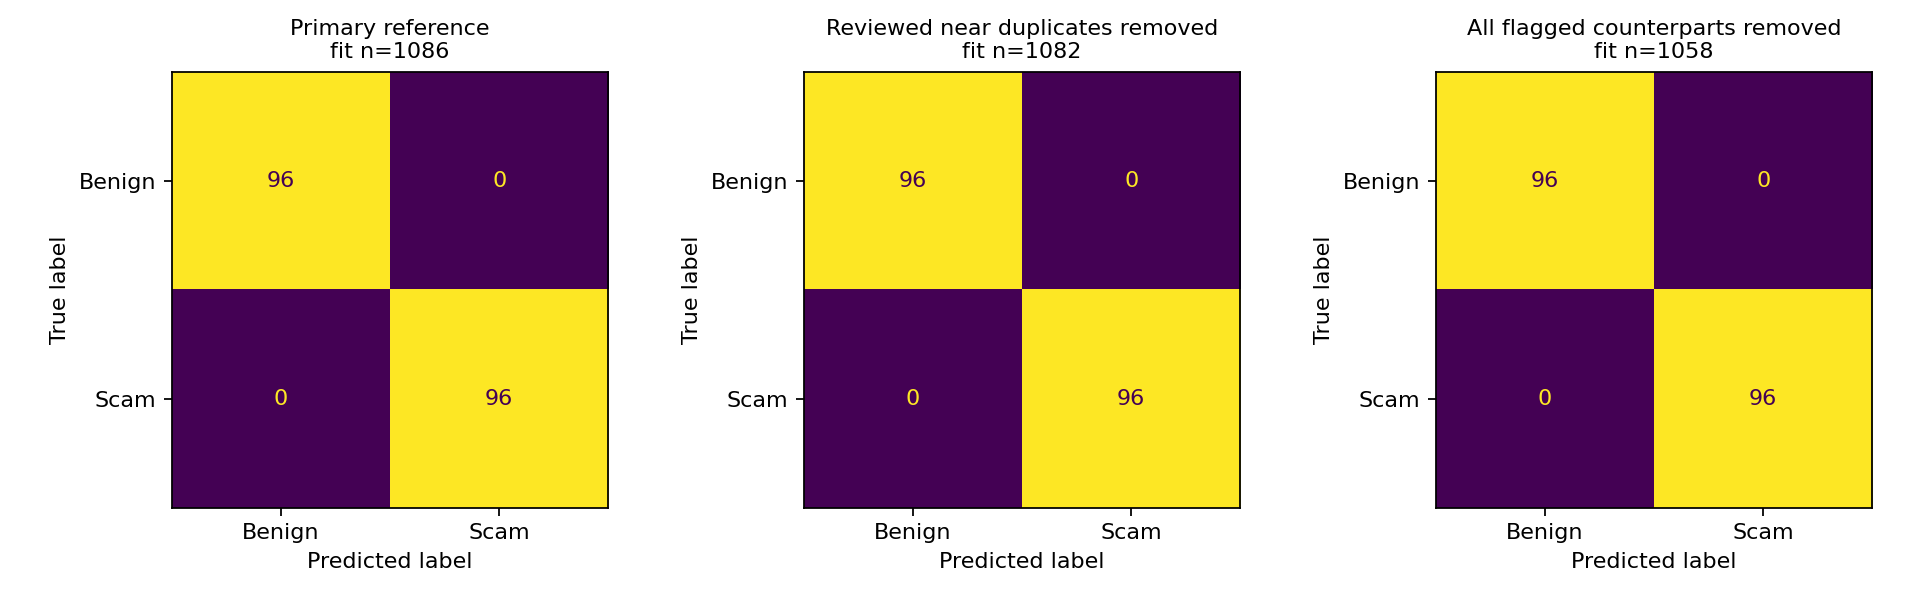

{'train_validation_flagged_pairs': 30,
 'confirmed_near_verbatim_pairs': 4,
 'validation_membership_unchanged': True,
 'original_reference_artifacts_unchanged': True}

Even perfect sensitivity performance does not establish same-topic intent discrimination or real-world generalization. No independently reviewed challenge set has been evaluated.


In [6]:
display(pd.read_csv(OUTPUT_DIR / "overlap_decisions.csv"))
display(pd.read_csv(OUTPUT_DIR / "overlap_sensitivity_metrics.csv"))
display(pd.read_csv(OUTPUT_DIR / "overlap_sensitivity_by_type.csv"))
display(Image(filename=str(OUTPUT_DIR / "overlap_sensitivity_confusion_matrices.png")))
display(summary["review_scope"])
print(summary["limits"])
assert summary["test_evaluated"] is False
assert summary["review_scope"]["original_reference_artifacts_unchanged"]


## Interpretation and handoff

Passing implementation and shuffled-label controls reduces concern about a coding
leak. Passing overlap sensitivity shows whether these specific removals affect
this validation result. Neither demonstrates intent discrimination within a topic.
Next, preregister a fixed supplemental set of legitimate refunds/support and
fraudulent delivery/insurance calls; collect independent teammate labels before
scoring. Keep original benchmark results and diagnostics separate. Hugo should
account for topic/template shortcuts when interpreting fusion scores.

Save the artifacts before releasing the runtime. CLI 0.6.0 can continue after cell
errors; verify saved outputs and match cell source hashes to actual kernel history.


In [7]:
import json
import shutil

assert (OUTPUT_DIR / "diagnostic_summary.json").exists()
assert (OUTPUT_DIR / "label_shuffle_metrics.csv").exists()
assert (OUTPUT_DIR / "overlap_sensitivity_metrics.csv").exists()
archive = shutil.make_archive(str(ROOT / "text_diagnostic_artifacts"), "zip", OUTPUT_DIR)
print("Diagnostic archive:", archive)


Diagnostic archive: /content/text_diagnostic_artifacts.zip
